In [1]:
from part_2 import RaceSimulator, plot_tires, find_best_strategy

In [2]:
simulator = RaceSimulator()
print(simulator.tire_data)

        Tmin  Tmax   alpha  beta
soft       0    10  0.5000    15
medium     1    10  0.2500    25
hard       2    10  0.0625    55


In [3]:
# Test Soft tire at different ages
soft_time = simulator.tire_time(10, 0, 10, 0.5, 15)
print("Soft tire:", soft_time)

# Test Medium tire
medium_time = simulator.tire_time(10, 1, 10, 0.25, 25)
print("Medium tire:", medium_time)

# Test Hard tire
hard_time = simulator.tire_time(10, 2, 10, 0.0625, 55)
print("Hard tire:", hard_time)

Soft tire: 0.7585818002124355
Medium tire: 1.2067963291902306
Hard tire: 2.4532194024637906


In [4]:
total = simulator.simulate(
    [20, 20, 20],
    ['Soft', 'Medium', 'Hard']
)

print("Total time added:", total)
print(simulator.race_data)

Total time added: 174.30127951442554
    Lap    Tire  Tire Age  Tire Time Added  Pit Stop Time
0     1    soft         0         0.005528            0.0
1     2    soft         1         0.009111            0.0
2     3    soft         2         0.015012            0.0
3     4    soft         3         0.024726            0.0
4     5    soft         4         0.040701            0.0
5     6    soft         5         0.066929            0.0
6     7    soft         6         0.109869            0.0
7     8    soft         7         0.179862            0.0
8     9    soft         8         0.293122            0.0
9    10    soft         9         0.474259            0.0
10   11    soft        10         0.758582            0.0
11   12    soft        11         1.192029            0.0
12   13    soft        12         1.824255            0.0
13   14    soft        13         2.689414            0.0
14   15    soft        14         3.775407            0.0
15   16    soft        15         5

# Normal race 

In [5]:
# test a normal race 
print("Total time added:", total)
print("Number of laps:", len(simulator.race_data))
print("Number of pit stops:", (simulator.race_data['Pit Stop Time'] > 0).sum())
print(simulator.race_data.head())

Total time added: 174.30127951442554
Number of laps: 60
Number of pit stops: 2
   Lap  Tire  Tire Age  Tire Time Added  Pit Stop Time
0    1  soft         0         0.005528            0.0
1    2  soft         1         0.009111            0.0
2    3  soft         2         0.015012            0.0
3    4  soft         3         0.024726            0.0
4    5  soft         4         0.040701            0.0


# Uneven stints 

In [6]:

total = simulator.simulate(
    [15, 25, 20],
    ['Medium', 'Soft', 'Hard']
)

print("Total time added:", total)
print("Number of laps:", len(simulator.race_data))
print(simulator.race_data.tail())

Total time added: 211.8976355499724
Number of laps: 60
    Lap  Tire  Tire Age  Tire Time Added  Pit Stop Time
55   56  hard        15         2.606865            0.0
56   57  hard        16         2.642860            0.0
57   58  hard        17         2.680792            0.0
58   59  hard        18         2.720744            0.0
59   60  hard        19         2.762796            0.0


# Test Case: invalid stint lengths 

In [ ]:
simulator.simulate([20, 20, 15], ['Soft', 'Medium', 'Hard'])

ValueError: Total number of laps must be 60

# Test Case: only one tire type 

In [8]:
simulator.simulate([20, 20, 20], ['Soft', 'Soft', 'Soft'])

ValueError: At least 2 different tire types must be used

# Test Case: bad tire name 

In [9]:
simulator.simulate([20, 20, 20], ['Soft', 'Medium', 'Ultra'])

ValueError: Unknown tire type

# Test Case: not using RaceSimulator Class

In [10]:
class Fake:
    pass

wrong_class = Fake()
plot_tires(wrong_class)

TypeError: simulator must be a RaceSimulator, got Fake

# Plot Tire Graph

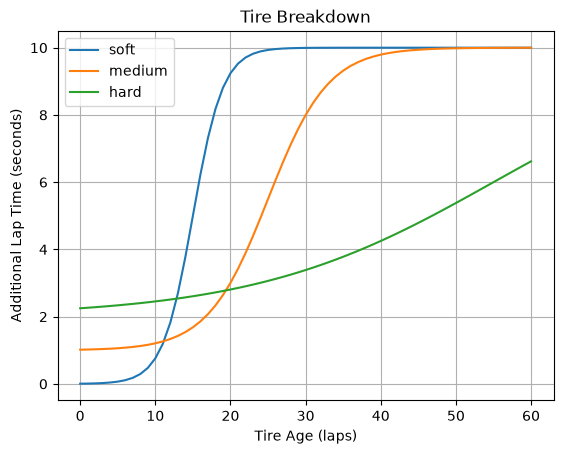

In [11]:
plot_tires(simulator)

# Find Best Time

In [12]:
best_time, best_stints, best_tires = find_best_strategy(simulator)

print("Best total time:", best_time)
print("Best stint lengths:", best_stints)
print("Best tire strategy:", best_tires)

Best total time: 134.2730167184821
Best stint lengths: [22, 23, 15]
Best tire strategy: ['medium', 'medium', 'soft']
